# # Praktikum 1 — Klasifikasi Gambar Day vs Night (HOG + Neural Network)
#
# Jobsheet **JS15: Pipeline Machine Learning and Deployment** — JTI Polinema 2025/2026.
#
# Notebook ini mereplikasi Langkah 1–12 modul: memuat dataset citra, resize 256×256,
# encoding label (`day`=1, `night`=0), ekstraksi fitur **HOG** (`orientations=9`,
# `pixels_per_cell=(8,8)`, `cells_per_block=(2,2)`, `block_norm='L2-Hys'`),
# normalisasi **StandardScaler**, split validasi 20%, model Dense 128→64→1 (sigmoid),
# `adam` + `binary_crossentropy`, 20 epoch, lalu **menyimpan artefak deployment**
# (`day_night_model.h5` + `scaler.pkl`) ke folder `../deploy/`.
#
# **Deviasi dari modul (disengaja):**
# - Modul memakai `from google.colab import drive; drive.mount('/content/drive')`.
#   Di mesin lokal tidak ada Colab/Drive, jadi mount diganti path lokal relatif
#   terhadap notebook: `data/images/{training,test}/`. Struktur folder,
#   nama file, dan isi gambar identik dengan dataset modul.
# - Seed dipatok (`SEED = 42`) untuk numpy, TensorFlow, dan `train_test_split`
#   supaya hasil bisa direproduksi.
# - `model.save` dan `pickle.dump` menulis langsung ke folder `deploy/` (artefak
#   siap dipakai Praktikum 2), bukan ke root Colab.

In [1]:
# Shim agar path konsisten saat notebook dieksekusi dari direktori mana pun.
import os
__file__ = os.path.abspath("praktikum1_day_night_hog.ipynb")

# ## Langkah 1: Import Library
#
# Sama seperti modul, kecuali baris `google.colab.drive` (lihat catatan deviasi di atas).

In [2]:
from pathlib import Path
import json
import pickle
import random

import numpy as np
import matplotlib.pyplot as plt  # backend inline bawaan kernel Jupyter (grafik tampil + tersimpan)
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE = Path(__file__).resolve().parent          # .../praktikum-1
ROOT = BASE.parent                              # .../js15-pipeline-machine-learning-and-deployment
DATA = ROOT / "data" / "images"
OUT = BASE / "output"
DEPLOY = ROOT / "deploy"
OUT.mkdir(exist_ok=True)
DEPLOY.mkdir(exist_ok=True)

print("TensorFlow :", tf.__version__)
print("OpenCV     :", cv2.__version__)
print("Folder data:", DATA)

TensorFlow : 2.15.1
OpenCV     : 4.10.0
Folder data: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\data\images


# ## Langkah 2: Load Dataset
#
# Membaca gambar dari direktori *training* dan *testing*, menyimpannya bersama label
# (nama subfolder: `day` / `night`). Path mengarah ke salinan dataset lokal
# (`data/images/`) — bukan lagi `/content/drive/MyDrive/...` seperti di modul.

In [3]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list


train_dir = DATA / "training"
test_dir = DATA / "test"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")
print("Contoh ukuran citra asli:", train_img[0][0].shape, "| label:", train_img[0][1])

Jumlah data training: 240
Jumlah data testing: 160
Contoh ukuran citra asli: (458, 800, 3) | label: day


# ## Langkah 3: Preprocessing (Resize & Label Encoding)
#
# Resize semua citra ke 256×256 dan ubah label teks menjadi biner: `day`=1, `night`=0.

In [4]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)


def label_encoder(label):
    return 1 if label == 'day' else 0


def preprocess(img_list):
    X, y = [], []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y


X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

print("Jumlah train:", len(X_train_img), "| ukuran tiap citra:", X_train_img[0].shape)
print("Jumlah test :", len(X_test_img))
print("Distribusi label train (1=day, 0=night):", np.bincount(y_train))

Jumlah train: 240 | ukuran tiap citra: (256, 256, 3)
Jumlah test : 160
Distribusi label train (1=day, 0=night): [120 120]


# ## Langkah 4: Ekstraksi Fitur HOG
#
# Parameter HOG sama persis dengan modul. Untuk citra 256×256 dengan sel 8×8
# dihasilkan grid 32×32 sel → 31×31 blok → dimensi vektor fitur
# `31 × 31 × 2 × 2 × 9 = 34596`.

In [5]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)


X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

print("Dimensi fitur HOG train:", X_train_feat.shape)
print("Dimensi fitur HOG test :", X_test_feat.shape)

Dimensi fitur HOG train: (240, 34596)
Dimensi fitur HOG test : (160, 34596)


# Visualisasi HOG satu citra `day` dan satu citra `night` (memastikan deskriptor
# menangkap struktur tepi yang berbeda antara siang dan malam).

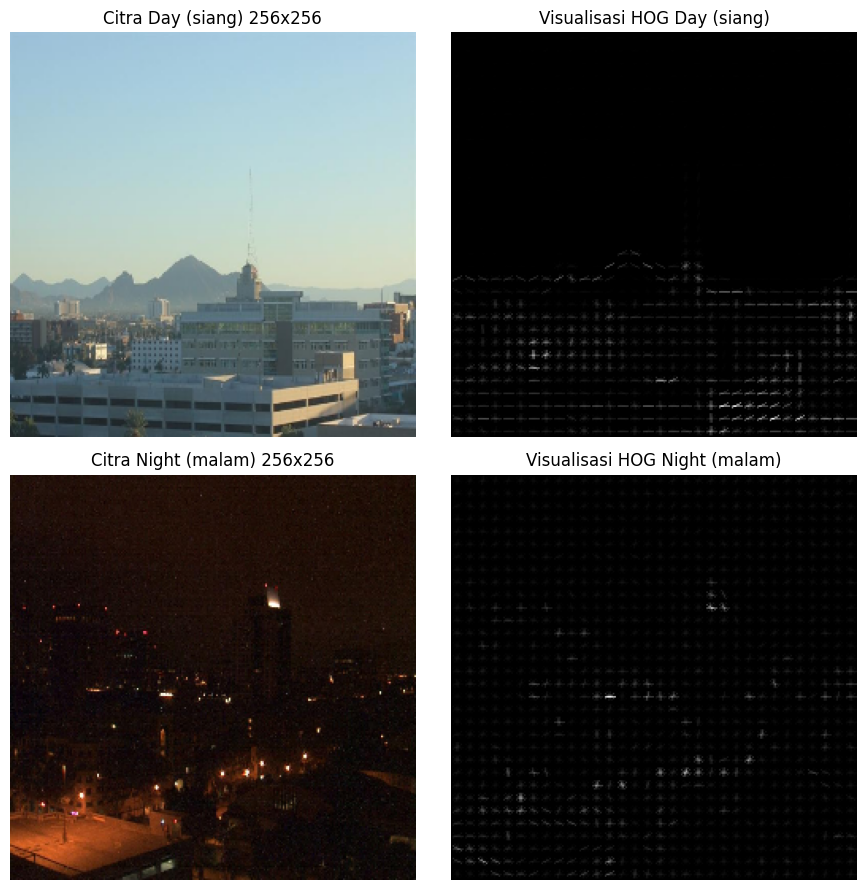

Grafik disimpan: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\praktikum-1\output\contoh_hog.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for row, (label_cari, judul) in enumerate([("day", "Day (siang)"), ("night", "Night (malam)")]):
    idx = next(i for i, (_, lb) in enumerate(train_img) if lb == label_cari)
    img = X_train_img[idx]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), block_norm='L2-Hys',
                     visualize=True, feature_vector=True)
    axes[row, 0].imshow(img); axes[row, 0].set_title(f"Citra {judul} 256x256"); axes[row, 0].axis("off")
    axes[row, 1].imshow(hog_img, cmap="gray"); axes[row, 1].set_title(f"Visualisasi HOG {judul}"); axes[row, 1].axis("off")
plt.tight_layout()
plt.savefig(OUT / "contoh_hog.png", dpi=110)
plt.show()
print("Grafik disimpan:", OUT / "contoh_hog.png")

# ## Langkah 5: Normalisasi Fitur
#
# `StandardScaler` di-*fit* hanya pada data training, lalu dipakai untuk transform
# data test (mencegah kebocoran informasi). Scaler inilah yang nanti ikut disimpan
# ke `scaler.pkl` dan wajib dipakai ulang saat inference.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

print("Bentuk X_train_scaled:", X_train_scaled.shape)
print("Rata-rata fitur (setelah scaling):", round(float(X_train_scaled.mean()), 6))
print("Std fitur (setelah scaling)     :", round(float(X_train_scaled.std()), 6))

Bentuk X_train_scaled: (240, 34596)
Rata-rata fitur (setelah scaling): 0.0
Std fitur (setelah scaling)     : 1.0


# ## Langkah 6 & 7: Split Train/Validation dan Konversi Label

In [8]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=SEED
)

# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape, "| y_val:", y_val.shape, "| y_test:", y_test.shape)

X_train: (192, 34596) | X_val: (48, 34596) | X_test_scaled: (160, 34596)
y_train: (192,) | y_val: (48,) | y_test: (160,)


# ## Langkah 8: Arsitektur Model
#
# `Dense(128, relu) → Dense(64, relu) → Dense(1, sigmoid)`, optimizer `adam`,
# loss `binary_crossentropy`.

In [9]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 128)               4428416   


 dense_1 (Dense)             (None, 64)                8256      


 dense_2 (Dense)             (None, 1)                 65        


Total params: 4436737 (16.92 MB)


Trainable params: 4436737 (16.92 MB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


# ## Langkah 9: Training (20 epoch, batch 32)

In [10]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=2
)

Epoch 1/20


6/6 - 4s - loss: 0.9021 - accuracy: 0.7969 - val_loss: 0.0387 - val_accuracy: 0.9792 - 4s/epoch - 734ms/step


Epoch 2/20


6/6 - 0s - loss: 0.0465 - accuracy: 0.9896 - val_loss: 7.5396e-04 - val_accuracy: 1.0000 - 350ms/epoch - 58ms/step


Epoch 3/20


6/6 - 0s - loss: 0.0057 - accuracy: 0.9948 - val_loss: 3.1751e-04 - val_accuracy: 1.0000 - 334ms/epoch - 56ms/step


... (30 outputs left out)

Epoch 19/20


6/6 - 0s - loss: 2.0872e-07 - accuracy: 1.0000 - val_loss: 9.3726e-05 - val_accuracy: 1.0000 - 379ms/epoch - 63ms/step


Epoch 20/20


6/6 - 0s - loss: 2.0649e-07 - accuracy: 1.0000 - val_loss: 9.3725e-05 - val_accuracy: 1.0000 - 410ms/epoch - 68ms/step


# ## Langkah 10: Evaluasi pada Data Test

In [11]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Akurasi Test:", test_acc)
print("Loss Test   :", test_loss)

Akurasi Test: 0.949999988079071
Loss Test   : 0.7107537388801575


# ## Langkah 11: Prediksi, Classification Report, dan Confusion Matrix

In [12]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["night (0)", "day (1)"]))
print(confusion_matrix(y_test, y_pred))

report_dict = classification_report(y_test, y_pred, target_names=["night", "day"], output_dict=True)

              precision    recall  f1-score   support

   night (0)       0.93      0.97      0.95        80
     day (1)       0.97      0.93      0.95        80

    accuracy                           0.95       160
   macro avg       0.95      0.95      0.95       160
weighted avg       0.95      0.95      0.95       160

[[78  2]
 [ 6 74]]


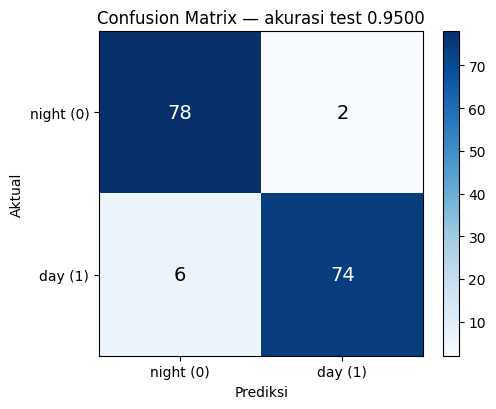

In [13]:
# Confusion matrix sebagai gambar
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax.set_xticks([0, 1], ["night (0)", "day (1)"])
ax.set_yticks([0, 1], ["night (0)", "day (1)"])
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
ax.set_title(f"Confusion Matrix — akurasi test {test_acc:.4f}")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=110)
plt.show()

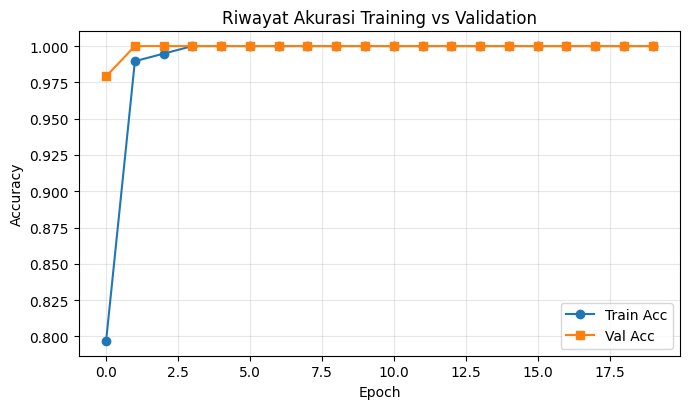

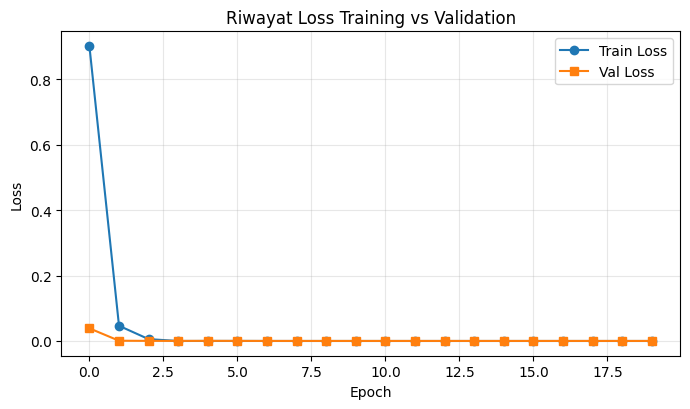

In [14]:
# Grafik riwayat training
plt.figure(figsize=(7, 4.2))
plt.plot(history.history['accuracy'], marker="o", label='Train Acc')
plt.plot(history.history['val_accuracy'], marker="s", label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.title("Riwayat Akurasi Training vs Validation")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(OUT / "training_history.png", dpi=110)
plt.show()

plt.figure(figsize=(7, 4.2))
plt.plot(history.history['loss'], marker="o", label='Train Loss')
plt.plot(history.history['val_loss'], marker="s", label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title("Riwayat Loss Training vs Validation")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(OUT / "training_loss.png", dpi=110)
plt.show()

# ## Langkah 12: Menyimpan Model (`.h5`) dan Scaler (`.pkl`)
#
# Kedua file ditulis ke folder `deploy/` — artefak inilah yang di-`COPY` ke dalam
# image Docker pada Praktikum 2.

In [15]:
MODEL_PATH = DEPLOY / "day_night_model.h5"
SCALER_PATH = DEPLOY / "scaler.pkl"

model.save(MODEL_PATH)
print("✅ Model berhasil disimpan sebagai:", MODEL_PATH)

with open(SCALER_PATH, 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai:", SCALER_PATH)

print("\nUkuran artefak:")
for p in (MODEL_PATH, SCALER_PATH):
    print(f"  {p.name:22s} {p.stat().st_size/1024:8.1f} KB")

C:\code\pemmes26\.venv\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


✅ Model berhasil disimpan sebagai: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\deploy\day_night_model.h5
✅ Scaler berhasil disimpan sebagai: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\deploy\scaler.pkl

Ukuran artefak:
  day_night_model.h5      52024.1 KB
  scaler.pkl                811.3 KB


# ## Verifikasi Artefak: Muat Ulang lalu Prediksi
#
# Bukti bahwa file benar-benar bisa dipakai ulang di lingkungan berbeda
# (ini yang dilakukan `app.py` Flask saat start): load `.h5` + `.pkl`,
# lalu prediksi satu citra test.

In [16]:
loaded_model = tf.keras.models.load_model(MODEL_PATH)
with open(SCALER_PATH, 'rb') as f:
    loaded_scaler = pickle.load(f)


def predict_path(img_path, model=loaded_model, scaler=loaded_scaler):
    """Pipeline inference persis seperti app.py: baca → RGB → 256x256 → gray → HOG → scaler."""
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm='L2-Hys',
               visualize=False, feature_vector=True)
    prob = float(model.predict(scaler.transform(feat.reshape(1, -1)), verbose=0)[0][0])
    return prob, ("Day (Siang)" if prob > 0.5 else "Night (Malam)")


contoh = sorted((DATA / "test" / "day").glob("*.jpg"))[0]
prob, label = predict_path(contoh)
print("File diuji      :", contoh.name)
print("Probabilitas day:", round(prob, 6))
print("Prediksi        :", label)
print("Label sebenarnya: Day (Siang)" if contoh.parent.name == "day" else "Label sebenarnya: Night (Malam)")
assert abs(prob - float(loaded_model.predict(scaler.transform(X_test_feat[[0]]), verbose=0)[0][0])) < 1e-6
print("\n✅ Artefak .h5 + .pkl berhasil dimuat ulang dan memberi prediksi konsisten.")

File diuji      : 20151101_152050.jpg
Probabilitas day: 1.0
Prediksi        : Day (Siang)
Label sebenarnya: Day (Siang)



✅ Artefak .h5 + .pkl berhasil dimuat ulang dan memberi prediksi konsisten.


# ## Ringkasan Hasil (dievaluasi dari output nyata)
#
# Sel di bawah menuliskan metrik ke `output/metrics.csv` dan mencetak ringkasan
# yang dipakai di README.

In [17]:
metrics = {
    "n_train": len(X_train),
    "n_val": len(X_val),
    "n_test": int(len(y_test)),
    "dimensi_hog": int(input_dim),
    "test_accuracy": round(float(test_acc), 6),
    "test_loss": round(float(test_loss), 6),
    "precision_day": round(report_dict["day"]["precision"], 4),
    "recall_day": round(report_dict["day"]["recall"], 4),
    "f1_day": round(report_dict["day"]["f1-score"], 4),
    "seed": SEED,
}
with open(OUT / "metrics.csv", "w", encoding="utf-8") as f:
    f.write("metrik,nilai\n")
    for k, v in metrics.items():
        f.write(f"{k},{v}\n")

print(json.dumps(metrics, indent=2))
print("\n✅ Metrik tersimpan di", OUT / "metrics.csv")

{
  "n_train": 192,
  "n_val": 48,
  "n_test": 160,
  "dimensi_hog": 34596,
  "test_accuracy": 0.95,
  "test_loss": 0.710754,
  "precision_day": 0.9737,
  "recall_day": 0.925,
  "f1_day": 0.9487,
  "seed": 42
}

✅ Metrik tersimpan di C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\praktikum-1\output\metrics.csv
